# Day 8 Exercises: Backpropagation

Student version with gaps.

## Context

This lab opens the training black box from Day 7. You will manually implement backpropagation twice: first for a shallow one-hidden-layer ReLU network, then for a deeper two-hidden-layer ReLU network. After that, you will compare your gradients with JAX's reverse-mode backpropagation and inspect why reverse mode is efficient for scalar neural-network losses.

The networks and batch are deliberately small. The point is not to obtain an impressive fit, but to see which values must be cached, how local derivative rules compose, and what JAX automates for us.

> #### Instructions
>
> Run the setup cells first. Complete the exercise-local implementation cells, then run the three exercises. Use the shape checks, gradient comparisons, and efficiency diagnostics to answer the open questions.
> The exercise cells use the functions from that block, so run each exercise after completing the relevant implementation functions.


## Learning Goals

The lecture describes backpropagation as reverse accumulation through a computational graph. This notebook turns that description into batch-oriented code for a shallow and a deep ReLU network.

By the end of the lab you should be able to:

- implement manual backpropagation for a shallow one-hidden-layer network;
- use manual gradients in gradient descent for a mean-squared-error loss;
- extend the same local derivative rules to a deeper two-hidden-layer network;
- compare manual gradients with JAX reverse-mode gradients from `jax.grad`;
- explain what JAX automates compared with a manual backpropagation implementation;
- compare reverse-mode backpropagation with forward-mode automatic differentiation for a scalar loss.


## Shared Backpropagation Workflow

### Notebook convention
Blocks labelled **Instructions** tell you what to do. Blocks labelled **Open questions** are the questions to answer after running the diagnostics.

### Structure
Both networks use the same data batch, activation function, MSE loss convention, local backward rules, and diagnostic helpers. The shallow network is the minimal case. The deep network shows that backpropagation is the same local mechanism repeated through more layers.

### What stays fixed?
The data batch, parameter dictionaries, mean-squared-error convention, local affine and ReLU backward rules, JAX reference gradients, gradient-comparison tables, and efficiency helpers are shared.

### What changes between exercises?
Exercise 1 asks you to implement manual backpropagation for the shallow and deep models. Exercise 2 compares both manual implementations with JAX backpropagation. Exercise 3 compares reverse-mode backpropagation with forward-mode AD from an efficiency viewpoint.


## Setup

The shared data, fixed networks, JAX references, shape checks, gradient-descent diagnostics, and forward/reverse-mode efficiency helpers live next to this notebook in `day8_helpers.py`. The notebook imports those provided pieces here; the implementation tasks remain inside the exercise sections below.

You may open `day8_helpers.py` if you want to inspect the provided infrastructure. This is optional: the core lab does not require reading or editing the helper file.

> #### Instructions
>
> Run this cell before starting the exercises. You do not need to edit the helper module during the core lab.


In [1]:
from pathlib import Path
import sys

# Make the local helper module importable when running from the day folder,
# the notebooks folder, the quarto folder, or the course root.
for helper_dir in [
    Path.cwd(),
    Path.cwd() / "day8",
    Path.cwd() / "notebooks" / "day8",
    Path.cwd() / "quarto" / "notebooks" / "day8",
]:
    if (helper_dir / "day8_helpers.py").exists():
        sys.path.insert(0, str(helper_dir))
        break

from day8_helpers import *  # Provided teaching infrastructure for this lab.


## Data and Parameter Inspection

This cell instantiates the two fixed networks and the tiny training batch. Part a uses the shallow network; part b uses the deep network. Both see the same batch, so differences in the backward pass come from graph depth, not from different data.

The printed shapes are meant to be used while reading the formulas in Exercise 1. For example, `W1` maps the input column to hidden activations, and each bias has one entry per hidden unit.

> #### Instructions
>
> Run the cell and inspect the parameter shapes before starting Exercise 1.


Shallow network parameters
--------------------------
W1:     (1, 3)  values= 3
b1:     (1, 3)  values= 3
W2:     (3, 1)  values= 3
b2:     (1, 1)  values= 1
Total parameters: 10

Deep network parameters
-----------------------
W1:     (1, 3)  values= 3
b1:     (1, 3)  values= 3
W2:     (3, 2)  values= 6
b2:     (1, 2)  values= 2
W3:     (2, 1)  values= 2
b3:     (1, 1)  values= 1
Total parameters: 17



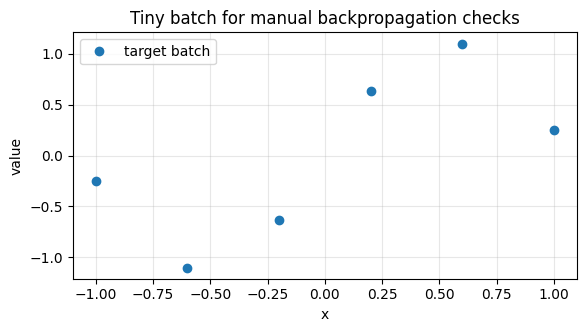

In [2]:
shallow_params = init_shallow_network()
deep_params = init_deep_network()
x_batch, y_batch = make_tiny_batch()

print_parameter_shapes("Shallow network parameters", shallow_params, SHALLOW_ORDER)
print_parameter_shapes("Deep network parameters", deep_params, DEEP_ORDER)
plot_batch_and_predictions(x_batch, y_batch)


## Exercise 1: Manual Backpropagation and Gradient Descent

**Part a** implements the neural network and its MSE gradient explicitly for the shallow network

$$
x \mapsto h_1=\sigma(W_1x+b_1), \qquad \hat y=W_2h_1+b_2.
$$

**Part b** repeats the same idea for the deep network

$$
x \mapsto h_1=\sigma(W_1x+b_1), \qquad h_2=\sigma(W_2h_1+b_2), \qquad \hat y=W_3h_2+b_3.
$$

After checking the one-pass gradients, the provided diagnostics use those manual gradients in gradient descent to reduce the same mean-squared-error loss.

> #### Instructions
>
> 1. Complete the activation/loss helper cell and the shallow forward pass.
> 2. Complete the shallow MSE-gradient code.
> 3. Complete the deep forward pass.
> 4. Complete the deep MSE-gradient code.
> 5. Run the diagnostics cell and inspect the cache shapes, gradient shapes, loss histories, and final fitted values.

> #### Further testing
>
> After the main diagnostic run, change one small setting if time permits and compare the table or plot before answering.
>
> #### Open questions
>
> 1. Which gradient formulas are reused in part a and part b?
> 2. Which additional cached values are needed for the deep network?
> 3. How do the MSE loss histories change during gradient descent for the shallow and deep networks?


In [3]:
# Exercise 1 activation and loss tasks

def relu(z):
    return jnp.where(z > 0.0, z, 0.0)


def relu_prime(z):
    return jnp.where(z > 0.0, 1.0, 0.0)


def mse_loss_and_output_adjoint(y_hat, y):
    """Return mean-squared error and d loss / d y_hat."""
    diff = y_hat - y
    loss = jnp.mean(diff ** 2)
    dy_hat = 2.0 * diff / y_hat.size
    return loss, dy_hat


> #### Instructions
>
> Complete the shallow-network forward pass. Cache the values that the backward pass will need.


In [4]:
def shallow_forward_with_cache(params, x):
    """Part a: explicit shallow network forward pass."""
    z1 = x @ params["W1"] + params["b1"]
    h1 = relu(z1)
    y_hat = h1 @ params["W2"] + params["b2"]
    cache = {"x": x, "z1": z1, "h1": h1, "y_hat": y_hat}
    return y_hat, cache


> #### Instructions
>
> Complete the shallow-network backward pass. Start from the MSE output adjoint, move through the output affine layer, then through the ReLU and first affine layer.


In [5]:
def shallow_manual_backward(params, cache, y):
    """Part a: explicit MSE gradient for the shallow network."""
    _, dy_hat = mse_loss_and_output_adjoint(cache["y_hat"], y)

    dW2 = cache["h1"].T @ dy_hat
    db2 = jnp.sum(dy_hat, axis=0, keepdims=True)

    dh1 = dy_hat @ params["W2"].T
    dz1 = dh1 * relu_prime(cache["z1"])

    dW1 = cache["x"].T @ dz1
    db1 = jnp.sum(dz1, axis=0, keepdims=True)

    return {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}


> #### Instructions
>
> Complete the deep-network forward pass. Cache every pre-activation and activation that the backward pass will need.


In [6]:
def deep_forward_with_cache(params, x):
    """Part b: explicit deep network forward pass."""
    z1 = x @ params["W1"] + params["b1"]
    h1 = relu(z1)
    z2 = h1 @ params["W2"] + params["b2"]
    h2 = relu(z2)
    y_hat = h2 @ params["W3"] + params["b3"]
    cache = {"x": x, "z1": z1, "h1": h1, "z2": z2, "h2": h2, "y_hat": y_hat}
    return y_hat, cache


> #### Instructions
>
> Complete the deep-network backward pass. Reuse the same local rules as in the shallow network, moving from the output layer back to the first layer.


In [7]:
def deep_manual_backward(params, cache, y):
    """Part b: explicit MSE gradient for the deep network."""
    _, dy_hat = mse_loss_and_output_adjoint(cache["y_hat"], y)

    dW3 = cache["h2"].T @ dy_hat
    db3 = jnp.sum(dy_hat, axis=0, keepdims=True)

    dh2 = dy_hat @ params["W3"].T
    dz2 = dh2 * relu_prime(cache["z2"])

    dW2 = cache["h1"].T @ dz2
    db2 = jnp.sum(dz2, axis=0, keepdims=True)

    dh1 = dz2 @ params["W2"].T
    dz1 = dh1 * relu_prime(cache["z1"])

    dW1 = cache["x"].T @ dz1
    db1 = jnp.sum(dz1, axis=0, keepdims=True)

    return {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2, "W3": dW3, "b3": db3}


> #### Instructions
>
> Choose the short diagnostic training settings and run the shared checks. This is where your forward and backward functions are checked against shapes and then used in manual gradient descent.
>
> A good starting point is `SHALLOW_LEARNING_RATE = 0.05`, `DEEP_LEARNING_RATE = 0.03`, and `N_STEPS = 120`. If the loss increases or becomes `nan`, reduce the learning rate by a factor of 2 to 10. If the loss barely changes, try values from `{0.01, 0.03, 0.05, 0.1}` while keeping `N_STEPS` around 100 to 200. The diagnostics use the full tiny batch, so there is no minibatch-size choice in Exercise 1.


In [8]:
SHALLOW_LEARNING_RATE = 0.05
DEEP_LEARNING_RATE = 0.03
N_STEPS = 120


> #### Instructions
>
> Run the manual-backpropagation diagnostics after choosing the short training settings.


Part a: shallow cache shapes
----------------------------
    x:     (6, 1)
   z1:     (6, 3)
   h1:     (6, 3)
y_hat:     (6, 1)

Part a: shallow manual gradient shapes
--------------------------------------
dW1:     (1, 3)
db1:     (1, 3)
dW2:     (3, 1)
db2:     (1, 1)



Part b: deep cache shapes
-------------------------
    x:     (6, 1)
   z1:     (6, 3)
   h1:     (6, 3)
   z2:     (6, 2)
   h2:     (6, 2)
y_hat:     (6, 1)

Part b: deep manual gradient shapes
-----------------------------------
dW1:     (1, 3)
db1:     (1, 3)
dW2:     (3, 2)
db2:     (1, 2)
dW3:     (2, 1)
db3:     (1, 1)



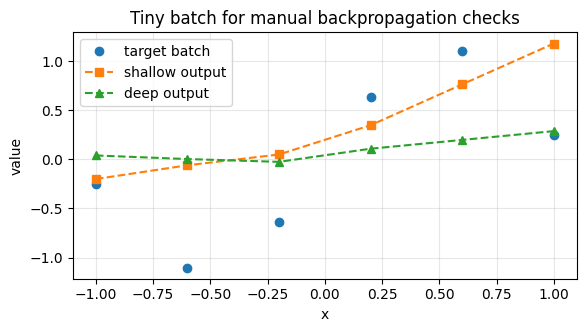

Part a: shallow manual-gradient descent
---------------------------------------
Initial MSE: 0.43697164
Final MSE:   0.25251525
Reduction:   0.18445638

Part b: deep manual-gradient descent
------------------------------------
Initial MSE: 0.46265499
Final MSE:   0.17106388
Reduction:   0.29159111



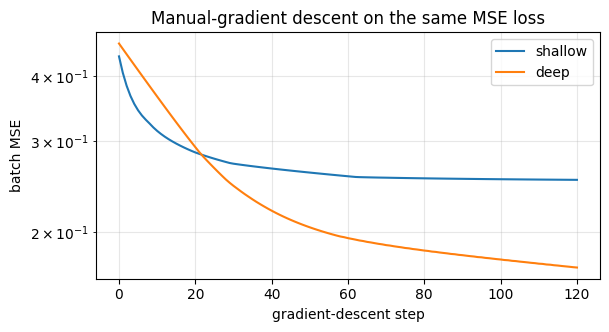

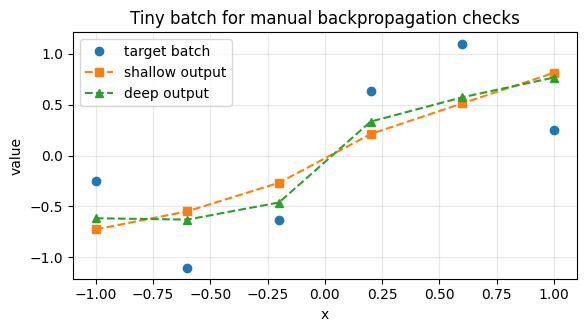

In [9]:
manual_backprop_results = run_manual_backpropagation_diagnostics(
    shallow_params,
    deep_params,
    x_batch,
    y_batch,
    shallow_forward_with_cache,
    shallow_manual_backward,
    deep_forward_with_cache,
    deep_manual_backward,
    relu,
    relu_prime,
    mse_loss_and_output_adjoint,
    shallow_learning_rate=SHALLOW_LEARNING_RATE,
    deep_learning_rate=DEEP_LEARNING_RATE,
    steps=N_STEPS,
)
shallow_manual_grads = manual_backprop_results["shallow_grads"]
deep_manual_grads = manual_backprop_results["deep_grads"]


> #### Further testing
>
> If time permits, change only `N_STEPS` or one learning rate and rerun the diagnostic.
>
> #### Open questions
>
> 1. Which cached shallow-network values were essential for the manual backward pass?
> 2. Which extra cache entries did the deep network need?
> 3. How do the shallow and deep MSE histories change during the short manual-gradient run?


#### Answers

1. **Shallow cache.** `z1` was essential to evaluate `relu_prime(z1)` when propagating the adjoint back through the hidden ReLU. `h1` was essential to form `dW2 = h1.T @ dy_hat`. `x` was essential to form `dW1 = x.T @ dz1`. `y_hat` was needed to compute the MSE output adjoint `dy_hat` in the first place.
2. **Deep cache.** The deep network additionally needed `z2` (for `relu_prime(z2)` at the second hidden layer) and `h2` (to form `dW3 = h2.T @ dy_hat`). These are exactly the same two roles that `z1`/`h1` already played, just one layer further out.
3. **Loss histories.** Over 120 manual-gradient steps, the shallow network (lr=0.05) went from MSE 0.43697 to 0.25252 (reduction 0.18446), while the deep network (lr=0.03) went from MSE 0.46265 to 0.17106 (reduction 0.29159). Both histories decrease monotonically and roughly log-linearly; the deep network, despite the smaller learning rate, reached a lower final MSE because its extra layer gives it more expressive power on this batch.


## Exercise 2: Compare With JAX Backpropagation

JAX's `jax.grad` applies reverse-mode automatic differentiation to the same scalar loss. In this exercise, JAX is the reference implementation of backpropagation. Your manual gradients should agree with it up to roundoff error.

> #### Instructions
>
> 1. Complete the two short JAX-gradient calls.
> 2. Run the comparison and one-step loss checks.
> 3. Use the maximum absolute errors to judge whether your manual gradients agree with JAX.

> #### Further testing
>
> After the main diagnostic run, change one small setting if time permits and compare the table or plot before answering.
>
> #### Open questions
>
> 1. Which parameter has the largest absolute discrepancy in the shallow comparison? What is its size?
> 2. Which parameter has the largest absolute discrepancy in the deep comparison? What is its size?
> 3. What does JAX automate that you had to write explicitly in Exercise 1?


In [10]:
shallow_reference_grads = shallow_jax_gradients(shallow_params, x_batch, y_batch)
deep_reference_grads = deep_jax_gradients(deep_params, x_batch, y_batch)


> #### Instructions
>
> Check the shallow manual gradients against JAX reverse-mode gradients, then run the one-step loss sanity check.


In [11]:
SHALLOW_GRADIENT_TOLERANCE = 1.0e-8


> #### Instructions
>
> Check the shallow manual gradients against JAX reverse-mode gradients, then run the one-step loss sanity check.


In [12]:
print_gradient_comparison(
    "Shallow manual gradients versus JAX backpropagation",
    shallow_manual_grads,
    shallow_reference_grads,
    SHALLOW_ORDER,
)
assert_gradient_agreement(
    shallow_manual_grads,
    shallow_reference_grads,
    SHALLOW_ORDER,
    atol=SHALLOW_GRADIENT_TOLERANCE,
)
print_loss_step(
    "Shallow one-step loss check",
    shallow_reference_loss,
    shallow_params,
    shallow_manual_grads,
    SHALLOW_ORDER,
    x_batch,
    y_batch,
)


Shallow manual gradients versus JAX backpropagation
---------------------------------------------------
name       shape   max abs error  relative error
 W1      (1, 3)       2.776e-17       1.776e-16
 b1      (1, 3)       2.776e-17       1.526e-16
 W2      (3, 1)       5.551e-17       1.997e-16
 b2      (1, 1)       1.110e-16       1.600e-16
Tree max abs error: 1.110e-16


Tree L2 error:      1.317e-16

Shallow one-step loss check
---------------------------
Loss before one manual-gradient step: 0.43697164
Loss after one manual-gradient step:  0.40617045



> #### Instructions
>
> Repeat the same JAX comparison for the deep network. Use the parameter-by-parameter table to locate any mismatch.


In [13]:
DEEP_GRADIENT_TOLERANCE = 1.0e-8


> #### Instructions
>
> Repeat the same JAX comparison for the deep network. Use the parameter-by-parameter table to locate any mismatch.


In [14]:
print_gradient_comparison(
    "Deep manual gradients versus JAX backpropagation",
    deep_manual_grads,
    deep_reference_grads,
    DEEP_ORDER,
)
assert_gradient_agreement(
    deep_manual_grads,
    deep_reference_grads,
    DEEP_ORDER,
    atol=DEEP_GRADIENT_TOLERANCE,
)
print_loss_step(
    "Deep one-step loss check",
    deep_reference_loss,
    deep_params,
    deep_manual_grads,
    DEEP_ORDER,
    x_batch,
    y_batch,
)


Deep manual gradients versus JAX backpropagation
------------------------------------------------
name       shape   max abs error  relative error
 W1      (1, 3)       1.388e-17       1.220e-16
 b1      (1, 3)       2.776e-17       1.067e-16
 W2      (3, 2)       0.000e+00       0.000e+00
 b2      (1, 2)       2.602e-17       7.777e-17
 W3      (2, 1)       3.469e-18       2.493e-17
 b3      (1, 1)       5.551e-17       2.713e-16
Tree max abs error: 5.551e-17


Tree L2 error:      6.880e-17

Deep one-step loss check
------------------------
Loss before one manual-gradient step: 0.46265499
Loss after one manual-gradient step:  0.44455597



> #### Further testing
>
> If a comparison fails, inspect the largest parameter-wise error before changing tolerances.
>
> #### Open questions
>
> 1. Which gradient entries agree to roundoff level?
> 2. What coding mistakes would produce a shape-correct but numerically wrong gradient?
> 3. What does JAX automate that you wrote explicitly in Exercise 1?


#### Answers

1. **Roundoff-level agreement.** Every parameter agrees with JAX to roundoff: the shallow tree max-abs-error is 1.110e-16 (relative errors ~1e-16 for W1, b1, W2, b2), and the deep tree max-abs-error is 5.551e-17 (relative errors ~1e-16 to 1e-17 for W1, b1, W2, b2, W3, b3, with W2 matching exactly to 0.0). None of the entries stand out as less accurate than the others.
2. **Shape-correct but wrong.** Mistakes such as forgetting the `relu_prime` mask (letting gradient flow through inactive units), transposing the wrong matrix (e.g. using `W2` instead of `W2.T` when propagating `dh1`), reusing the output adjoint `dy_hat` directly at an inner layer instead of the propagated `dh1`/`dh2`, summing the bias gradient over the wrong axis, or dropping the `2/N` factor in the MSE adjoint would all still produce arrays of the correct shape but numerically wrong values.
3. **What JAX automates.** `jax.grad` builds the computational graph during the forward pass and automatically applies the vector-Jacobian-product rule of each primitive operation in reverse; we never had to cache intermediate values ourselves, derive the local transposed-Jacobian rule for each layer, or hand-write the backward sweep -- JAX does all of that generically for any composition of differentiable primitives.


## Exercise 3: Efficiency of Backpropagation Versus Forward-Mode AD

For one scalar loss and many parameters, reverse mode computes the full gradient with one backward sweep after the forward pass. Forward mode naturally computes directional derivatives. To recover the full gradient by forward mode, one needs one direction per parameter.

The sweep-count table is the main diagnostic. The timing table is only illustrative because small JAX timings include overhead and depend on the machine.

> #### Instructions
>
> 1. Complete the short efficiency-table builder.
> 2. Run the diagnostics for hidden widths `2`, `8`, and `32`.
> 3. Compare shallow and deep parameter counts, cached scalar values, and sweep counts.
> 4. Inspect the small timing comparison for repeated JVP-based forward mode versus one reverse-mode gradient.

> #### Further testing
>
> After the main diagnostic run, change one small setting if time permits and compare the table or plot before answering.
>
> #### Open questions
>
> 1. How does the number of forward-mode sweeps scale with the number of parameters?
> 2. Why can reverse mode compute the full parameter gradient with one reverse sweep for a scalar loss?
> 3. What extra memory does reverse mode need, and when could forward mode still be preferable?


In [15]:
def make_efficiency_table(widths, batch_size=6):
    """Compare full-gradient sweep counts for forward and reverse mode."""
    rows = []
    for width in widths:
        for architecture in ("shallow", "deep"):
            layer_widths = [1, width, 1] if architecture == "shallow" else [1, width, width, 1]
            parameters = count_dense_parameters(layer_widths)
            cached_scalars = estimate_cached_scalars(layer_widths, batch_size)
            rows.append(
                {
                    "architecture": architecture,
                    "width": width,
                    "parameters": parameters,
                    "cached_scalars": cached_scalars,
                    "forward_mode_sweeps": parameters,
                    "reverse_mode_sweeps": 1,
                    "sweep_ratio": parameters / 1,
                }
            )
    return rows


> #### Instructions
>
> Choose the hidden widths for the conceptual sweep-count table and a smaller list for the illustrative timing check. The sweep counts are the main result; timings are secondary.
>
> Start with `widths = [2, 8, 32]` and `timing_widths = [2, 4, 8]`. The diagnostic cells use `batch_size=x_batch.shape[0]`, which is 6 for the fixed toy batch. If you experiment with the helper functions after the checks pass, try batch sizes such as 4, 8, or 16 and watch how cached scalars and timing change.


In [16]:
widths = [2, 8, 32]
timing_widths = [2, 4, 8]


> #### Instructions
>
> Run the sweep-count table and the small timing diagnostic after choosing the width lists.


architecture  width  parameters    cached   forward sweeps   reverse sweeps     ratio
--------------------------------------------------------------------------------------
     shallow      2           7        36                7                1       7.0
        deep      2          13        60               13                1      13.0
     shallow      8          25       108               25                1      25.0
        deep      8          97       204               97                1      97.0
     shallow     32          97       396               97                1      97.0
        deep     32        1153       780             1153                1    1153.0



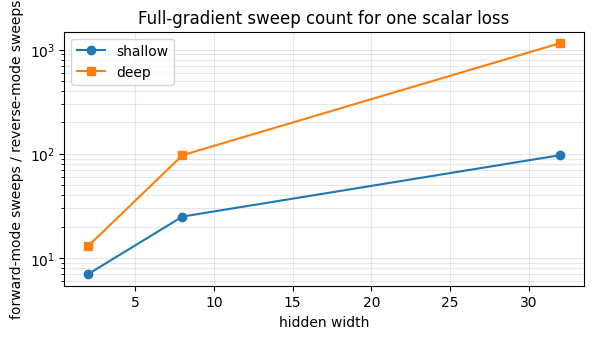

Illustrative timing: full gradient of a small deep network
---------------------------------------------------------
width  parameters    reverse ms    forward ms    max |diff|
    2          13        444.14        552.74     1.665e-16
    4          33        630.00        869.45     2.220e-16
    8          97       1173.91       1110.24     2.776e-17



In [17]:
efficiency_rows = make_efficiency_table(widths, batch_size=x_batch.shape[0])
check_efficiency_table(efficiency_rows, widths, batch_size=x_batch.shape[0])
print_efficiency_table(efficiency_rows)
plot_efficiency_table(efficiency_rows)

timing_rows = time_gradient_methods(timing_widths, batch_size=x_batch.shape[0])
print_timing_table(timing_rows)


> #### Further testing
>
> If the timing cell is slow on your machine, reduce `timing_widths` and keep the conceptual table unchanged.
>
> #### Open questions
>
> 1. How does the forward-mode sweep count scale with the number of parameters?
> 2. What information does reverse mode need to keep from the forward pass?
> 3. In what kind of derivative task could forward mode be the more natural choice?


#### Answers

1. **Forward-mode scaling.** Forward-mode sweep count equals the parameter count exactly in every row of the table (e.g. shallow width 32: 97 parameters -> 97 sweeps; deep width 32: 1153 parameters -> 1153 sweeps), so it scales linearly with the number of parameters. Reverse mode stays at exactly 1 sweep regardless of width or depth, so the ratio grows from 7x (shallow, width 2) up to 1153x (deep, width 32).
2. **What reverse mode must keep.** Reverse mode needs every cached pre-activation and activation from the forward pass (`z1`, `h1`, and, for the deep network, `z2`, `h2`, plus `y_hat`) for every sample in the batch -- the `cached_scalars` column, which grows with batch size, depth, and width (e.g. 780 scalars for the deep width-32 network). This memory is the price paid for needing only one backward sweep.
3. **When forward mode wins.** Forward mode is more natural when there are few input directions but many outputs, e.g. computing a small number of directional derivatives/JVPs, Jacobians of functions with many outputs and few parameters, or sensitivity analyses with only a handful of parameters (the opposite regime from training a network with a scalar loss and many parameters).


## Optional Extension: Input Derivatives as a Bridge to PINNs

PINNs use the same automatic-differentiation machinery, but often differentiate the network output with respect to the input variable as well as the parameters. The next cell computes one input derivative for the deep network.

> #### Instructions
>
> Run the optional cell if you have time. This is a preview of Day 9, not a required PINN implementation.


In [18]:
def scalar_deep_network_output(x_scalar):
    x = jnp.array([[x_scalar]], dtype=jnp.float64)
    return deep_reference_forward(deep_params, x)[0, 0]

x0 = 0.2
input_derivative = jax.grad(scalar_deep_network_output)(x0)
print(f"d y_hat / d x at x={x0}: {float(input_derivative):.6f}")


d y_hat / d x at x=0.2: 0.224000


## Reflection and Deliverable

> #### Instructions
>
> Before you finish, make sure that all exercise-local implementation gaps have been completed and all assertions pass. Then write short answers to the prompts below.

> #### Reflection questions
>
> 1. In part a, which cached shallow-network values were essential for the manual backward pass?
> 2. In part b, what changed when you extended the manual implementation to the deep network?
> 3. How did the MSE loss change when gradient descent used your manual gradients?
> 4. How close were your manual gradients to JAX backpropagation, and what would a large discrepancy suggest?
> 5. Why is reverse-mode backpropagation usually preferred over forward mode for neural-network training losses?

> #### Optional extensions
>
> - replace ReLU by `tanh` and adjust the activation derivative;
> - add one more hidden layer to the deep network;
> - compare forward finite differences with forward-mode JVPs for one parameter direction;
> - compute `d y_hat / d x` at several input points and plot the result.


#### My answers

1. In part a, the essential cached shallow values were `z1` (for the ReLU mask), `h1` (for `dW2`), `x` (for `dW1`), and `y_hat` (to compute the MSE output adjoint).
2. In part b, the only change was one more repetition of the same two local rules (affine transpose-Jacobian, then ReLU mask) to push the adjoint back through the second hidden layer; this required caching `z2` and `h2` in addition to `z1` and `h1`.
3. Using the manual gradients in gradient descent for 120 steps reduced the shallow-network MSE from 0.43697 to 0.25252 and the deep-network MSE from 0.46265 to 0.17106.
4. The manual gradients agreed with JAX's `jax.grad` to roundoff (tree max-abs-error of 1.11e-16 for the shallow network and 5.55e-17 for the deep network); a large discrepancy (much bigger than floating-point roundoff) would point to a bug such as a missing ReLU mask, a transposed matrix, or a wrong adjoint being propagated.
5. Reverse mode is preferred for a scalar training loss because the number of forward-mode sweeps needed to recover the full gradient scales with the number of parameters (up to 1153 sweeps for the widest deep network here), while reverse mode always needs exactly one backward sweep no matter how many parameters there are -- exactly what the Exercise 3 sweep-count table shows.


> #### Development note
>
> Codex, a generative AI tool, was used to help generate and refine this notebook.
